# Time-aware clustering and kNN feature analysis

This notebook explores how customer/observation patterns change as the observation date (`m0_monthenddate`) approaches. It:

1. Builds transaction-state features at configurable cut-offs before M0 (for example, 60, 30 and 0 days).
2. Clusters observations using scaled features and profiles the resulting clusters.
3. Trains a **k-nearest neighbours (kNN)** classifier with `sklearn.pipeline.make_pipeline`.
4. Estimates important features using **permutation importance** on held-out data.
5. Compares results across time cut-offs.

**Important:** set the target and data paths below. The default target is `target_value`. The notebook deliberately excludes outcome fields from model inputs and uses customer-grouped train/test splits so observations from the same customer do not leak across the split. If you need a strict future-period evaluation, use the optional temporal split section as well.

# Analysis

## Analysis from results using snapshot dataset

Analysis of the time-aware cluster profiles
The three files describe six customer-behaviour clusters at different points in time: 0d, 30d, and 60d. The most useful findings are the differences in target rate, financial activity, income regularity, and signs of financial distress.
1. Overall findings
Observations per snapshot
10,499
Same total across all three files


Overall target rate
51.9%
Weighted across clusters




Three patterns stand out:
- Low or absent income and high fees are associated with some of the highest target rates.
- Cash-heavy spending and high spending relative to income identify other potentially high-risk groups.
- High transaction volume alone does not identify the highest-risk customers. The very active clusters have target rates closer to the overall rate.
These are descriptive associations, not evidence that the features cause the target outcome. I am assuming that target_rate is the proportion of observations with target_value = 1.
2. Which clusters have the highest target rates?
The overall target rate is approximately 51.9%, so clusters substantially above that level are especially interesting.
Snapshot	Cluster	Observations	Target rate	Difference from overall
0d	5	747 (7.1%)	81.5%	+29.6 pp
0d	2	2,724 (25.9%)	63.3%	+11.4 pp
0d	0	545 (5.2%)	60.7%	+8.8 pp
30d	5	684 (6.5%)	80.1%	+28.2 pp
30d	1	494 (4.7%)	63.4%	+11.4 pp
30d	4	2,679 (25.5%)	62.8%	+10.9 pp
60d	1	958 (9.1%)	74.5%	+22.6 pp
60d	5	382 (3.6%)	63.9%	+11.9 pp
60d	4	3,051 (29.1%)	58.5%	+6.6 pp

pp = percentage points. Cluster numbers are assigned separately at each snapshot and should not be assumed to identify the same group across files.

The clearest result is the consistently high-risk, low-activity group. Cluster 5 at 0d and 30d has target rates above 80%, while the corresponding-looking low-activity, fee-heavy cluster at 60d (cluster 1) has a 74.5% target rate.

That is a promising pattern to investigate, but cluster labels are not stable identifiers. The profiles must be compared by their features, not their cluster numbers.
3. Interpreting the cluster profiles
A. Low activity, limited income, and high fees
0d — Cluster 5
81.5%
Target rate · 747 observations


30d — Cluster 5
80.1%
Target rate · 684 observations



These clusters show:
- Very few transactions: around 38 at 0d and 28 at 30d, compared with hundreds in more active clusters.
- Very low recorded income.
- A high proportion of observations with no income recorded: 59.3% at 0d and 70.3% at 30d.
- Fees accounting for roughly 67% and 75% of spend, respectively.

This is the strongest potential risk segment in the output. It may represent customers with little recorded financial activity and substantial fee exposure relative to their other transactions.

However, fees as a share of spending can be misleading when total spending is very low. A high percentage does not necessarily mean high absolute fees. The high no_income_seen rate also means the cluster should be described as having no recorded income, not necessarily no income whatsoever.
B. Cash-heavy customers with high spending relative to income
At 30d, cluster 1 has a 63.4% target rate. Its average profile includes:
- unemployed_now = 1.0, indicating the flag is set for the cluster's average profile.
- Cash accounting for about 22.5% of spending.
- spend_to_income of approximately 20.5.
- A target rate about 11.4 percentage points above the overall rate.
At 60d, cluster 5 has a similar pattern: spend_to_income is around 17.2, cash is about 23.4% of spending, and the target rate is 63.9%.

These profiles suggest that high spending relative to recorded income, cash use, and employment-related indicators may help distinguish risk. But check how spend_to_income is calculated: when income is near zero, this ratio can become extremely large or unstable. It should not be interpreted as a literal spending multiple without inspecting its denominator and handling of zero income.
C. High-volume financial activity
The unusually active clusters are small:
- 0d cluster 3: 75 observations, target rate 49.3%.
- 30d cluster 3: 100 observations, target rate 52.0%.
- 60d cluster 2: 95 observations, target rate 53.7%.
They have very high transaction counts and monetary flows, but their target rates are close to the overall rate. They also show high P2P payment shares and, in some cases, higher gambling shares.

This indicates that transaction volume and monetary scale alone may be poor risk indicators. These clusters may represent unusually active customers, outliers, or a distinct behavioural segment. Their small sizes also make their profiles sensitive to individual observations.
D. High spending and negative net flow, but lower target rates
At 0d, cluster 4 has a target rate of just 36.3%, despite average outflows exceeding inflows by approximately 13,528. At 30d, cluster 0 has a target rate of 37.6% and a negative average net flow of around 15,057. At 60d, cluster 0 has a target rate of 40.1% and negative net flow of around 13,551.

These clusters have comparatively high transaction activity and spending, yet lower target rates.

This is an important counterexample: negative net flow or high expenditure does not automatically imply a high target rate. The context of the customer's financial activity—income regularity, cash usage, fees, and other behavioural patterns—may matter more than any single measure.
4. What changes over time?
The profiles suggest that some risk-related behavioural patterns can be identified at different historical cut-offs, but there are important limitations to the comparison.
Pattern	60d	30d	0d
Low-activity, fee-heavy group	Cluster 1: 74.5%	Cluster 5: 80.1%	Cluster 5: 81.5%
Cash-heavy, high spending-to-income group	Cluster 5: 63.9%	Cluster 1: 63.4%	Cluster 2: 63.3%
Higher-activity, lower-target group	Cluster 0: 40.1%	Cluster 0: 37.6%	Cluster 4: 36.3%

These are similar-looking profiles, not tracked customer transitions. The cluster assignments are independently generated, and the files do not establish which customers move between clusters.

Also, days_covered averages about 31 days for 60d, 61 days for 30d, and 90 days for 0d. Consequently, raw transaction counts and monetary totals are not directly comparable across snapshots. Ratios and rates are generally more suitable for comparison, although they have their own limitations.
5. Implications for your kNN model
The cluster profiles provide useful hypotheses for feature selection, but they do not directly measure predictive feature importance.

I would prioritise investigating these features:
1. Income availability and recency: no_income_seen, days_since_last_income, days_since_last_uif, and unemployed_now.
2. Fee exposure: fees_share_of_spend, run_fees_slog, run_n_fees, and run_n_insufficient_fee.
3. Spending relative to inflows: spend_to_income, outflow_to_inflow, and net_to_inflow.
4. Cash behaviour: cash_share_of_spend, grp_cash_withdrawal_share, and run_n_cash.
5. Transaction activity: run_n_txn, n_txn_per_day, and days_covered.
6. Spending composition: gambling, essential spending, debt repayment, and P2P payment shares.
These are candidate features to test—not a confirmed ranking. Some are mathematically related, and ratios can be unstable when their denominators are close to zero.

For a defensible analysis:
- Evaluate kNN using a customer-level holdout split, so observations from the same customer cannot leak across training and testing.
- Calculate permutation importance on held-out data, preferably using balanced accuracy or macro-F1 if class imbalance is a concern.
- Compare feature importance across the 60d, 30d, and 0d models.
- Compare against a baseline model and test whether cluster membership itself adds predictive value.
Conclusion
The most promising finding is the repeated association between low recorded income, limited transaction activity, and high fee exposure and elevated target rates. Cash-heavy behaviour and extreme spending-to-income ratios provide additional signals worth testing. Conversely, high transaction volumes and negative net flows alone do not reliably identify high-risk groups.

The next step is to validate these patterns using held-out kNN performance and permutation importance. That will establish whether the apparent cluster differences genuinely improve prediction rather than merely describing the data.

## Full Transaction Analysis

Full-history clustering and kNN: results analysis
The results suggest that transaction behaviour contains useful information about the target, but the six clusters differ substantially in both target rate and size. The kNN model also performs better than a balanced-accuracy baseline of 0.50, although the clustering structure is weak and the individual features provide only modest predictive improvements.

One important distinction: these results describe the target coded as 1. Whether that represents default, repayment failure, or another outcome depends on your target definition.
1. Overall results
Observations
10,499

Predictor features
141

Overall target rate
51.94%

kNN balanced accuracy
62.89%



Silhouette score
0.0762


The data was split into 8,416 training observations and 2,083 test observations, using a customer-grouped holdout. This is preferable to a random row split because it reduces the risk of the same customer appearing in both sets.

There are two different conclusions here:
- Classification: balanced accuracy of 0.6289 suggests the model identifies the target better than chance, though performance remains moderate.
- Clustering: a silhouette score of 0.0762 indicates that the clusters overlap substantially. The six clusters should be treated as broad behavioural segments rather than sharply separated customer types.
The target is fairly balanced overall: 5,453 observations have target 1, and 5,046 have target 0. Consequently, balanced accuracy is a useful metric, since it gives equal weight to performance on both classes.
2. Cluster-level analysis
The overall target rate is 51.94%. The table below compares each cluster with that baseline.
Cluster	Observations	Share	Target rate	Difference vs overall
0	686	6.5%	79.45%	+27.51 pp
1	2,056	19.6%	36.48%	−15.46 pp
2	559	5.3%	61.72%	+9.78 pp
3	92	0.9%	50.00%	−1.94 pp
4	2,787	26.5%	62.11%	+10.17 pp
5	4,319	41.1%	47.14%	−4.80 pp

Target rate by cluster
The dashed reference is the overall target rate of 51.94%.

0%25%50%75%100%012345








Cluster	Rate
0	79.45
1	36.48
2	61.72
3	50
4	62.11
5	47.14







The main findings are:
- Cluster 0 has the highest target rate, at 79.45%, but represents only 6.5% of observations.
- Cluster 1 has the lowest target rate, at 36.48%, making it the clearest lower-target segment.
- Cluster 4 combines a high target rate with substantial size: 26.5% of observations have a target rate of 62.11%.
- Cluster 5 is the largest segment, representing 41.1% of the dataset, but its target rate is slightly below the overall average.
- Cluster 3 is too small for strong conclusions. Its 92 observations and 50% target rate provide little evidence of a distinctive target pattern.
A high target rate and a large number of target-positive observations are not the same thing. Cluster 0 has the highest rate, but cluster 4 contains 1,731 target-positive observations, while cluster 5 contains 2,036 because it is much larger. This distinction matters if the objective is to identify the largest number of target-positive customers rather than the most concentrated segment.
3. Interpreting the six clusters
The cluster profiles contain transaction activity, inflows, outflows, income sources, spending categories, balances, fee activity, and behavioural ratios. The strongest interpretations are below.
Cluster 0 — High target rate, low recorded income, fee-heavy
Share of observations
6.5%

Target rate
79.45%


This cluster has approximately 42 transactions per observation, but relatively low recorded income (about 853) and low recorded spending (about 1,990). Its mean fee-related outflow is about 723, and fees account for approximately 60.4% of spending.

Other distinguishing characteristics include:
- 56.6% have no_income_seen = 1.
- The average time since the last recorded income is about 70 days.
- Fee-related activity, including insufficient-funds fees, is elevated.
- Average balance is negative, at approximately −4,090.
The combination of high target rate, low recorded income, and substantial fee exposure makes this a particularly interesting segment to investigate. It may reflect financial strain, but the cluster statistics alone cannot establish the cause.

Practical implication: investigate whether fee exposure and the absence or recency of recorded income can improve early identification of the target outcome.
Cluster 1 — High transaction activity, lowest target rate
Share of observations
19.6%

Target rate
36.48%


Cluster 1 is characterised by high transaction volume and substantial financial flows:
- Approximately 640 transactions per observation.
- Mean inflow of about 214,904 and outflow of about 229,264.
- Mean spending of approximately 168,385 and income of 111,677.
- Mean net flow of approximately −14,360.
- Outflow-to-inflow ratio of approximately 1.13.
Despite the negative average net flow, this cluster has the lowest target rate.

This is an important finding: negative net cash flow alone is not a reliable indicator of the target outcome. Customers with high transaction activity and substantial inflows and outflows may have a very different behavioural profile from customers with little recorded income and high fee exposure.

The cluster may also contain customers with higher financial throughput, so the absolute monetary values should be interpreted alongside the other clusters' different activity levels.
Cluster 2 — Unemployment-benefit income and elevated target rate
Share of observations
5.3%

Target rate
61.72%


This cluster is strongly distinguished by unemployment-related income:
- unemployed_now is 1 for all observations in the cluster.
- Recorded unemployment-related inflows are much higher than average.
- Mean income is approximately 23,064.
- Mean spending is approximately 48,476.
- Cash accounts for about 21.6% of spending.
The target rate is almost 10 percentage points above the overall average.

This suggests that income source and employment-related indicators may help distinguish customer groups. However, the results do not show that unemployment itself causes the outcome. The cluster is small, and employment-related features may overlap with other financial characteristics.
Cluster 3 — Very high financial throughput, inconclusive target rate
Share of observations
0.9%

Target rate
50.00%


This is a small, high-volume segment, with mean inflows of approximately 1.08 million, outflows of 1.10 million, and spending of 743,458. Gambling spending averages about 73,859.

Despite these unusually high values, its target rate is close to the overall rate.

The small sample of 92 observations means this cluster could be sensitive to outliers or a few unusual customers. It should not be used to draw broad conclusions about high-volume financial activity.
Cluster 4 — Large, cash-heavy segment with elevated target rate
Share of observations
26.5%

Target rate
62.11%


Cluster 4 is the largest segment with a clearly elevated target rate. It has approximately 98 transactions, mean income of 14,972, spending of 20,639, and net flow of +9,103.

Notable characteristics include:
- Cash represents approximately 27.8% of spending.
- Fee share is approximately 6.0%.
- Mean balance is around −1,415.
- Activity is lower than in Cluster 1, while cash-related spending is more prominent.
The elevated target rate makes this segment relevant from a population-level perspective. It contains 1,731 target-positive observations, the second-largest count among the six clusters.

Practical implication: cash-withdrawal behaviour, spending composition, and income measures are worth testing together rather than interpreting any single one as a risk factor.
Cluster 5 — Largest, broadly active segment with near-average target rate
Share of observations
41.1%

Target rate
47.14%


Cluster 5 contains the largest share of observations. It has about 309 transactions, mean income of 42,837, spending of 62,445, and net flow close to zero (−343).

Its target rate is slightly below the overall average. It is therefore a broad, relatively ordinary segment rather than a highly concentrated target-positive group.

Although it contains 2,036 target-positive observations, that is primarily a consequence of its size. Its target rate is not especially high.

4. What the cluster differences reveal
The standardised feature-difference file helps explain what separates each cluster from the overall dataset. These are differences in feature means measured in standard deviations, not causal effects.
Cluster	Strongest distinguishing patterns
0	High fee share, no recorded income, income recency, low recorded income and spending
1	High transaction and purchase counts, high financial throughput, relatively low cash share
2	Unemployment-benefit income, unemployment indicator, lower employment income
3	Extremely high spending, inflows, outflows and peer-to-peer flows
4	High cash share and comparatively low transaction activity
5	More moderate, diversified spending and income profile

Several observations follow.

First, income is not one-dimensional. The amount of income, its source, and how recently it was recorded describe different aspects of a customer's finances. Employment income, unemployment-related income, savings drawdowns, and the absence of observed income may each contribute different information.

Second, the composition of spending appears informative. Cash share, gambling share, and spending-category variables distinguish some groups, but their usefulness for predicting individual outcomes must be evaluated separately.

Third, transaction volume alone is insufficient. The high-volume Cluster 1 has a lower-than-average target rate, while the very high-volume Cluster 3 has a near-average rate. The relationship between activity and the target depends on the broader financial profile.

Fourth, ratios need caution. Features such as spend_to_income can become very large when the income denominator is small. For Cluster 2, for example, the mean spend-to-income ratio is approximately 17.9. That value should not be interpreted as a typical individual ratio without checking the distribution and denominator handling.
5. kNN permutation importance
Permutation importance estimates how much the model's balanced accuracy changes when one feature is shuffled on the held-out test data. A positive value means shuffling that feature worsened performance; a negative value means performance improved after shuffling it.

The highest-ranked features were:
Feature	Mean importance
run_in_income_employment	0.00452
run_in_savings_drawdown_slog	0.00364
run_grp_alcohol_tobacco_slog	0.00293
run_grp_food_groceries	0.00245
grp_household_upkeep_share	0.00240
run_grp_health	0.00229
grp_gambling_share	0.00220
gambling_share_of_spend	0.00220
run_in_income_other	0.00191
run_grp_family_education_slog	0.00185

These values are small. For example, the importance of run_in_income_employment is about 0.0045, equivalent to a decrease of roughly 0.45 percentage points in balanced accuracy when shuffled, based on the reported mean.
What this suggests
- Income source: employment income and savings drawdowns appear among the strongest individual predictors.
- Spending composition: groceries, health, household upkeep, alcohol/tobacco, and gambling-related features contribute some predictive information.
- Multiple signals matter: no single feature dominates the results. Prediction appears to depend on a combination of financial characteristics.
However, these are model-specific predictive associations, not causal explanations. For example, the importance of gambling-related spending does not establish that gambling causes the target outcome.
Why are many importance values negative?
Of the 141 features, 40 have positive mean importance and 101 have negative mean importance.

Negative importance does not mean that a feature is necessarily harmful in every model. It means that shuffling it improved balanced accuracy in this particular evaluation. Possible explanations include:
- The feature contributes noise rather than useful information.
- Several features contain overlapping information.
- The model is sensitive to the particular test sample.
- The importance estimates are noisy.
Some standard deviations are larger than the corresponding mean importance. For example, run_grp_alcohol_tobacco_slog has a mean importance of 0.00293 and a standard deviation of 0.00530. That makes its ranking uncertain.

The two gambling-share features also have identical importance values, suggesting they may be duplicate or nearly identical representations. More generally, the dataset contains raw monetary features, log-transformed versions, and ratios. Their overlapping information makes individual feature rankings less straightforward to interpret.

Conclusion: use these results to identify candidate feature groups for further testing, rather than treating the top-ranked features as a definitive ranking of importance.
6. Does clustering improve prediction?
The current outputs do not establish that clustering improves kNN performance.

The notebook uses K-means to discover segments and then separately trains kNN on the transaction features. This gives two different types of insight:
- Clustering describes the structure of the data and the target rates within each segment.
- Permutation importance estimates which features the fitted kNN relies on for held-out predictions.
The silhouette score of 0.0762 suggests the six segments overlap considerably. Nonetheless, clustering may still be useful for descriptive analysis, customer segmentation, or investigating groups with particularly high target rates.

To determine whether clustering adds predictive value, compare the same customer-grouped holdout across:
1. A kNN model using the original transaction features.
2. The same model with cluster membership added as a predictor.
3. A simple baseline model.
Use balanced accuracy, macro-F1, and per-class precision and recall. The current metrics file contains balanced accuracy but not the complete held-out classification report, so conclusions about precision and recall cannot be drawn from these files alone.
7. Important limitations
Before using the findings in a report or operational model, I would address the following issues.
A. “Full history” is still limited by the available extract
The average days_covered across clusters is approximately 94–102 days. This suggests that the available transaction history is still only around three months for many observations.

Removing the explicit lookback window does not create additional historical data. I would describe this analysis as using all available pre-M0 history, not necessarily a complete lifetime history.
B. Cluster 3 is very small
Only 92 observations belong to Cluster 3. Its unusually high financial values may be driven by a small number of customers. Consider inspecting individual distributions and quantiles, rather than relying exclusively on means.
C. Cluster profiles use means
Monetary features are often highly skewed. A small number of large values can inflate averages, particularly for transaction volume and spending. Medians and 25th/75th percentiles would help establish whether each profile is representative of most cluster members.
D. Ratios may be unstable
Ratios such as spend_to_income, outflow_to_inflow, and balance_runway_days require careful treatment of zero or near-zero denominators. Review their distributions and confirm how the feature engineering handles these cases.
E. Avoid interpreting associations causally
A high target rate in a cluster does not establish that its defining characteristics cause the target. These patterns should be validated on unseen customers and interpreted in the context of how the target was defined.
F. Check the target timing
Ensure that all transaction features are available at the prediction time. If the target is defined using a future repayment or collection outcome, no future transactions or outcome-derived fields should enter the predictors.
8. Recommended next steps
I would prioritise the following work.

1. Validate predictive performance

Generate the full held-out classification report, including balanced accuracy, macro-F1, precision and recall for each class. Compare against a baseline on exactly the same split.




2. Consolidate redundant features

Examine correlations between raw, logged, and ratio-based features. Test a smaller, carefully selected feature set, especially for income sources, spending composition, fees, and transaction activity.




3. Test whether cluster membership helps

Compare kNN with and without the cluster label, retaining the customer-grouped split. Fit all preprocessing and feature selection using training data only.




4. Test stability

Repeat evaluation across several customer-grouped splits or grouped cross-validation folds. Check whether the high-target clusters and top features remain consistent.



Overall conclusion
The clearest descriptive finding is that the target rate varies substantially across transaction-behaviour segments. Cluster 0 has a particularly high target rate and is characterised by low recorded income and high fee exposure. Cluster 4 is also important because it combines an elevated target rate with a large share of the population. By contrast, the high-activity Cluster 1 has the lowest target rate, demonstrating that large transaction volumes or negative net flows are not sufficient indicators on their own.

The predictive results are more modest. kNN achieves 62.89% balanced accuracy, while individual permutation-importance values are small and often noisy. Income-source features and spending composition are promising candidates, but the current evidence does not establish that any single feature is a strong predictor or that clustering improves prediction.

My recommendation: focus next on a rigorous held-out model comparison and a smaller, more interpretable feature set. This will establish whether the observed behavioural patterns translate into reliable predictive improvement.

# Windowed Discovery

## 1. Configuration

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 0

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"
M0_DATE = "m0_monthenddate"

# Each value is the number of days BEFORE M0 at which transaction state is measured.
AS_OF_DAYS = [60, 30, 0]

TEST_SIZE = 0.20
N_NEIGHBORS = 24
N_CLUSTERS = 6
PERMUTATION_REPEATS = 5

# For a quick initial run, optionally sample observations; set to None for all rows.
MAX_OBSERVATIONS = None

## 2. Load cleaned data and check keys

In [2]:
from clean_data import load_and_clean
clients, transactions, report = load_and_clean("snapshot/snapshot.parquet")

Observation key: ['obs_id']
Observation-level columns (17): ['cifwithcheckdigit', 'obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag']
Transaction-level columns (8): ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname']
Ignored when matching duplicates (row counters): []
Building clients table ...
  4,482,046 raw rows -> 10,499 observations (4,999 customers) (1s)
Building transactions table ...
  transactions batch 1/1: 3,534,387 rows kept (3s)
CLIENTS (one row per observation)                                             
  raw rows (observation fields repeated per transaction)             4,482,046
  observations after cleaning                                           10,499
  distinct

## 3. Build time-aware transaction features

The supplied `features_transactions.py` exposes `build_running_features`. Each snapshot measures the transaction state at a particular number of days before M0. A cut-off farther from M0 is useful for early-warning analysis; `as_of=0` uses state at M0.

Keep feature creation separate from the target. Never add `target_value`, `total_paid`, `payment_count`, `target_rule`, or other post-M0 outcome fields to `X`.

In [3]:
import features_transactions as ft

snapshot_features = {}
for days in AS_OF_DAYS:
    print(f"Building features at {days} days before M0...")
    snapshot_features[days] = ft.build_running_features(
        clients=clients,
        txns=transactions,
        as_of=days,
        batch_customers=20_000,
        by_group=True,
        log_money=True,
        verbose=True,
    )

for days, frame in snapshot_features.items():
    print(f"as_of={days}: shape={frame.shape}, unique obs_id={frame.index.nunique()}")

Building features at 60 days before M0...
  running features batch 1/1 done
Building features at 30 days before M0...
  running features batch 1/1 done
Building features at 0 days before M0...
  running features batch 1/1 done
as_of=60: shape=(10499, 142), unique obs_id=10499
as_of=30: shape=(10499, 142), unique obs_id=10499
as_of=0: shape=(10499, 142), unique obs_id=10499


## 4. Prepare modelling data safely

In [4]:
# Columns that are identifiers, dates, or outcomes rather than model predictors.
EXCLUDE_EXACT = {
    TARGET, "target_rule", "total_paid", "payment_count",
    OBS_ID, CUSTOMER_ID, M0_DATE,
}
EXCLUDE_PREFIXES = ("target_",)

def make_xy(feature_frame, clients_frame):
    # Feature index is obs_id; align labels and grouping variables by obs_id.
    meta = clients_frame.set_index(OBS_ID)
    ids = feature_frame.index.intersection(meta.index)
    X = feature_frame.loc[ids].copy()
    y = meta.loc[ids, TARGET].copy()
    groups = meta.loc[ids, CUSTOMER_ID].copy()
    dates = meta.loc[ids, M0_DATE].copy()

    valid = y.notna() & groups.notna()
    X, y, groups, dates = X.loc[valid], y.loc[valid], groups.loc[valid], dates.loc[valid]

    # Remove any feature that looks like a target/outcome or a direct identifier.
    drop_cols = [
        c for c in X.columns
        if c in EXCLUDE_EXACT or any(str(c).startswith(p) for p in EXCLUDE_PREFIXES)
    ]
    X = X.drop(columns=drop_cols, errors="ignore")

    # Convert bools to numeric; handle any accidental non-numeric feature as categorical.
    for col in X.select_dtypes(include=["bool"]).columns:
        X[col] = X[col].astype("int8")
    return X, y, groups, dates

X_by_time = {}
y_by_time = {}
groups_by_time = {}
dates_by_time = {}

for days, frame in snapshot_features.items():
    X_by_time[days], y_by_time[days], groups_by_time[days], dates_by_time[days] = make_xy(frame, clients)
    print(f"{days:>3} days: X={X_by_time[days].shape}, target classes={y_by_time[days].nunique()}")

display(X_by_time[AS_OF_DAYS[0]].head())

 60 days: X=(10499, 141), target classes=2
 30 days: X=(10499, 141), target classes=2
  0 days: X=(10499, 141), target classes=2


,run_n_txn,run_inflow,run_outflow,run_net,run_spend,run_income,run_essentials,run_nonessential,run_gambling,run_cash,...,run_in_income_informal_slog,run_in_income_unemployment_slog,run_in_borrowing_slog,run_in_savings_drawdown_slog,run_in_refunds_windfalls_slog,run_in_transfers_in_slog,run_in_other_inflow_slog,run_min_balance_slog,run_max_balance_slog,balance_slog
obs_id,,,,,,,,,,,,,,,,,,,,,
167,71.0,29304.81,49796.79,-20491.98,49773.26,29179.23,16656.35,1505.74,0.0,18500.0,...,0.000000,0.0,0.000000,0.0,4.484245,3.199897,2.736962,-10.544054,10.070739,6.391817
168,90.0,157979.43,46336.83,111642.60,45913.91,30837.59,18493.67,0.00,0.0,12800.0,...,7.583695,0.0,11.038513,0.0,5.707110,6.049545,11.038608,-10.547025,10.046612,-10.530230
169,58.0,96002.70,34817.60,61185.10,34515.24,31221.41,6448.23,0.00,0.0,14600.0,...,7.578590,0.0,10.345382,0.0,5.707110,5.714920,10.345382,-10.547025,10.124668,-10.540203
170,71.0,97222.80,45992.21,51230.59,45983.73,33015.13,11935.31,0.00,0.0,15165.0,...,7.588896,0.0,10.345382,0.0,0.000000,2.249184,10.345382,-10.554727,9.839328,-10.554727
171,54.0,101697.84,42372.27,59325.57,42367.27,37466.63,6184.07,0.00,0.0,14000.0,...,7.602476,0.0,10.345382,0.0,0.000000,1.791759,10.345382,-10.554727,10.095591,5.341760


## 5. Cluster the observations

K-means is applied to imputed and standardised numeric features. The cluster labels are **unsupervised descriptions**, not predictions of `target_value`. We use a reproducible sample for silhouette scoring because it can be expensive on large datasets.

For mixed categorical/numeric features, this notebook uses the numeric transaction-state features produced by `features_transactions.py`. If you add raw categorical fields, encode them inside a preprocessing pipeline before clustering.

In [5]:
def numeric_matrix(X):
    # KMeans requires numeric columns. Keep numeric features only; the feature builder
    # is expected to return numeric engineered features.
    X_num = X.select_dtypes(include=[np.number, "bool"]).copy()
    X_num = X_num.replace([np.inf, -np.inf], np.nan)
    # Drop columns that contain no observed values or have no variation.
    X_num = X_num.dropna(axis=1, how="all")
    X_num = X_num.loc[:, X_num.nunique(dropna=True) > 1]
    return X_num

cluster_results = {}
cluster_profiles = {}

for days in AS_OF_DAYS:
    X = numeric_matrix(X_by_time[days])
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    Z = prep.fit_transform(X)

    km = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(Z)

    # Silhouette score on a capped sample to control runtime.
    if len(Z) > 5000:
        rng = np.random.default_rng(RANDOM_STATE)
        sample_idx = rng.choice(len(Z), size=5000, replace=False)
        sil = silhouette_score(Z[sample_idx], labels[sample_idx])
    elif len(np.unique(labels)) > 1 and len(Z) > N_CLUSTERS:
        sil = silhouette_score(Z, labels)
    else:
        sil = np.nan

    result = pd.DataFrame({
        OBS_ID: X.index,
        "cluster": labels,
        "target": y_by_time[days].reindex(X.index).to_numpy(),
    }).set_index(OBS_ID)

    cluster_results[days] = result
    # Profiles in original units are more interpretable than standardised values.
    profile = X.assign(cluster=labels).groupby("cluster").mean(numeric_only=True)
    profile["n_observations"] = result.groupby("cluster").size()
    profile["target_rate"] = result.groupby("cluster")["target"].mean()
    cluster_profiles[days] = profile

    print(f"as_of={days}: silhouette={sil:.3f}")
    display(profile.sort_values("n_observations", ascending=False).head(N_CLUSTERS))

as_of=60: silhouette=0.070


,run_n_txn,run_inflow,run_outflow,run_net,run_spend,run_income,run_essentials,run_nonessential,run_gambling,run_cash,...,run_in_borrowing_slog,run_in_savings_drawdown_slog,run_in_refunds_windfalls_slog,run_in_transfers_in_slog,run_in_other_inflow_slog,run_min_balance_slog,run_max_balance_slog,balance_slog,n_observations,target_rate
cluster,,,,,,,,,,,,,,,,,,,,,
3,128.702850,31108.185907,33500.775095,-2392.589188,26174.085587,17447.937796,6695.764216,3693.435964,867.584898,3532.305589,...,1.880071,0.170259,1.191029,7.514541,4.704700,-9.085167,9.190006,3.022475,4210,0.459857
4,42.397902,12861.469993,10468.364523,2393.105470,8828.639443,6218.940000,1577.232776,595.849020,186.208148,2544.668797,...,3.036430,0.314644,0.559013,4.120924,4.955680,-8.599305,8.041105,-0.258607,3051,0.585054
0,254.420965,82920.766911,96471.626916,-13550.860006,71843.452002,43019.948996,19398.849573,12388.550250,2528.311836,5720.899285,...,1.888194,0.124595,2.109269,9.199358,5.908057,-9.900862,10.127266,5.017502,1803,0.400998
1,15.427975,6705.009969,874.317610,5830.692359,724.444979,249.673820,75.344885,37.815668,7.485386,56.263048,...,4.308478,0.709255,0.281558,0.923453,5.825784,-8.765388,2.162001,-4.047744,958,0.745303
5,94.162304,24507.458691,24502.989398,4.469293,17468.745209,5512.492513,4661.395916,2386.862304,494.986649,3155.104319,...,4.095602,0.501672,0.898494,6.253948,6.043335,-8.821079,8.782568,1.884315,382,0.638743
2,364.189474,457446.902000,464994.392211,-7547.490211,306450.008105,219497.171263,51372.906211,55204.997789,25736.405263,12983.355053,...,1.987333,0.299786,2.680285,10.461067,7.243007,-10.126936,11.679510,6.517483,95,0.536842


as_of=30: silhouette=0.082


,run_n_txn,run_inflow,run_outflow,run_net,run_spend,run_income,run_essentials,run_nonessential,run_gambling,run_cash,...,run_in_borrowing_slog,run_in_savings_drawdown_slog,run_in_refunds_windfalls_slog,run_in_transfers_in_slog,run_in_other_inflow_slog,run_min_balance_slog,run_max_balance_slog,balance_slog,n_observations,target_rate
cluster,,,,,,,,,,,,,,,,,,,,,
2,206.919991,50957.196259,52685.129394,-1727.933134,41340.809927,27682.052865,10224.005122,5600.004534,1372.959822,6108.163383,...,3.736492,0.222531,1.520611,8.046228,6.315872,-9.078581,9.257762,2.058390,4387,0.466606
4,63.496081,21278.230623,14370.736529,6907.494095,12326.259085,8726.111064,2047.735838,817.410597,285.589309,3823.354352,...,5.279789,0.407118,0.671532,4.408400,6.593133,-8.729535,7.976762,-0.803093,2679,0.628219
0,441.123898,139128.873457,154186.097155,-15057.223698,114678.111425,73296.535374,31441.472056,19370.087954,4027.603332,9365.088821,...,3.753556,0.175900,2.706749,9.817131,7.474665,-9.924839,10.193995,4.408873,2155,0.375870
5,28.330409,13877.955322,1150.893787,12727.061535,1017.369708,353.565117,68.921974,35.936257,3.885234,81.418129,...,5.910640,0.731452,0.273259,1.030063,6.971338,-8.859135,2.449049,-4.076654,684,0.801170
1,171.506073,43248.157571,43157.838360,90.319211,30252.181275,10572.988259,7915.964980,4749.983826,1319.595749,5146.068360,...,6.137319,0.521549,1.211470,7.059954,7.319652,-8.937217,9.003712,1.685979,494,0.633603
3,623.970000,740329.583600,773341.637700,-33012.054100,513716.159700,358986.734300,81675.743500,86280.025900,42618.750000,22338.739400,...,3.702562,0.417470,3.586379,10.818503,8.802187,-10.384896,11.880449,5.623595,100,0.520000


as_of=0: silhouette=0.080


,run_n_txn,run_inflow,run_outflow,run_net,run_spend,run_income,run_essentials,run_nonessential,run_gambling,run_cash,...,run_in_borrowing_slog,run_in_savings_drawdown_slog,run_in_refunds_windfalls_slog,run_in_transfers_in_slog,run_in_other_inflow_slog,run_min_balance_slog,run_max_balance_slog,balance_slog,n_observations,target_rate
cluster,,,,,,,,,,,,,,,,,,,,,
1,271.512105,6.868754e+04,6.847677e+04,210.776025,53277.475024,36506.258741,12984.580150,7324.018054,1885.884107,7632.459154,...,4.941651,0.247851,1.754137,8.442147,7.104851,-9.128001,9.354239,3.931856,4337,0.461148
2,82.965492,2.771338e+04,1.857325e+04,9140.125863,15935.928366,11309.085885,2685.399618,1035.306164,348.629758,4938.820775,...,6.016703,0.407978,0.741042,4.898020,7.086587,-8.717283,8.190702,0.777319,2724,0.632893
4,583.040077,1.890916e+05,2.026197e+05,-13528.030150,148128.893670,97391.303259,40605.182670,24646.459136,5247.860739,11821.239884,...,4.901422,0.235471,3.007059,10.138192,8.132619,-9.968559,10.290487,5.693526,2071,0.363110
5,38.294511,1.916781e+04,1.749653e+03,17418.159197,1576.579880,678.986372,92.590736,39.452490,4.310576,143.796519,...,6.287411,0.668790,0.329728,1.243973,7.313522,-8.915631,3.183205,-3.357260,747,0.815261
0,236.765138,6.645887e+04,6.237610e+04,4082.773835,44256.895083,20577.273303,10919.894991,6702.611266,1770.599450,7267.009578,...,7.304382,0.526490,1.452666,7.683009,8.043056,-8.986825,9.248449,3.114125,545,0.607339
3,897.293333,1.098254e+06,1.100592e+06,-2338.540667,734017.104267,581732.056800,100645.202667,126887.111600,64854.340000,28293.758667,...,5.088592,0.270337,4.127136,10.727580,9.392314,-10.195124,12.037565,6.046966,75,0.493333


### Cluster sizes and target rates across cut-offs

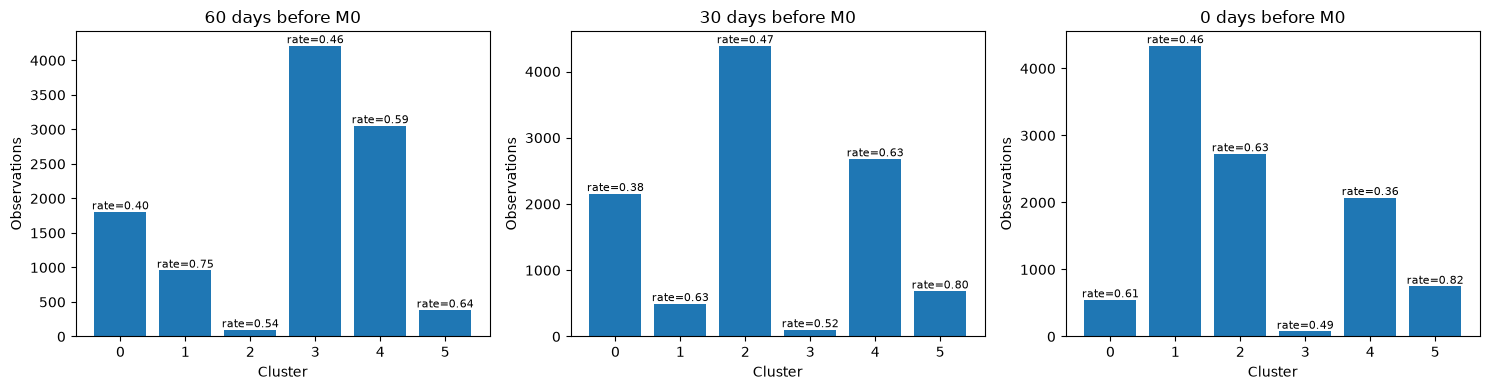

In [6]:
fig, axes = plt.subplots(1, len(AS_OF_DAYS), figsize=(5 * len(AS_OF_DAYS), 4), squeeze=False)
for ax, days in zip(axes[0], AS_OF_DAYS):
    counts = cluster_results[days]["cluster"].value_counts().sort_index()
    rates = cluster_results[days].groupby("cluster")["target"].mean().reindex(counts.index)
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"{days} days before M0")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Observations")
    for i, (count, rate) in enumerate(zip(counts.values, rates.values)):
        ax.text(i, count, f"rate={rate:.2f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### Which features distinguish each cluster?

The next cell computes each cluster's mean feature value relative to the overall mean, in standard-deviation units. This is a descriptive diagnostic, not a causal explanation. Use it to identify the variables that separate clusters, then inspect their original-scale distributions.

In [7]:
def cluster_standardised_differences(X, labels):
    Xn = numeric_matrix(X)
    overall_mean = Xn.mean()
    overall_sd = Xn.std().replace(0, np.nan)
    out = {}
    for cluster_id in sorted(pd.Series(labels).unique()):
        in_cluster = Xn.loc[np.asarray(labels) == cluster_id]
        out[cluster_id] = ((in_cluster.mean() - overall_mean) / overall_sd).sort_values(
            key=lambda s: s.abs(), ascending=False
        )
    return pd.DataFrame(out)

for days in AS_OF_DAYS:
    print(f"Top distinguishing features: {days} days before M0")
    diffs = cluster_standardised_differences(X_by_time[days], cluster_results[days]["cluster"].to_numpy())
    display(diffs.head(15))

Top distinguishing features: 60 days before M0


,0,1,2,3,4,5
balance,0.134538,-0.270477,1.432698,0.034534,-0.089907,0.023075
balance_runway_days,-0.058637,1.318340,0.022587,-0.044036,0.011489,-0.056771
balance_slog,0.497369,-0.885810,0.726236,0.192967,-0.307662,0.019306
cash_share_of_spend,-0.401119,-0.522774,-0.527066,-0.128081,0.548262,0.359798
committed_share_of_spend,0.017830,-0.596196,-0.362150,0.028068,0.129869,0.145122
days_covered,0.269557,-0.797705,0.185240,0.197007,-0.180049,-0.050990
days_since_last_income,-0.471770,1.745706,-0.395067,-0.387661,0.206500,0.570074
days_since_last_txn,-0.334791,1.053184,-0.233241,-0.241810,0.194797,0.111611
days_since_last_uif,0.299397,-0.404856,0.123116,0.258036,0.007751,-3.334127
essentials_share_of_spend,0.253127,-0.861413,-0.371891,0.175701,-0.116414,0.037913


Top distinguishing features: 30 days before M0


,0,1,2,3,4,5
balance,0.107046,0.096015,0.011807,0.639228,-0.093121,-0.211056
balance_runway_days,-0.036426,0.017469,-0.032959,-0.023400,0.008847,2.302344
balance_slog,0.473665,0.041076,0.100241,0.666650,-0.354366,-0.874441
cash_share_of_spend,-0.422067,0.307304,-0.075917,-0.556411,0.573714,-0.570973
committed_share_of_spend,0.092924,0.071121,-0.003951,-0.469083,0.126254,-0.744707
days_covered,0.262336,-0.034830,0.144402,0.268745,-0.225665,-0.882948
days_since_last_income,-0.496324,0.443727,-0.338643,-0.354455,0.357444,2.067043
days_since_last_txn,-0.372741,0.140766,-0.205921,-0.351726,0.345896,1.090075
days_since_last_uif,0.280175,-3.916328,0.244629,-0.043194,0.121824,-0.094071
essentials_share_of_spend,0.276787,0.055362,0.145703,-0.459379,-0.180099,-1.073977


Top distinguishing features: 0 days before M0


,0,1,2,3,4,5
balance,0.122839,0.011000,-0.088331,1.256665,0.102072,-0.240532
balance_runway_days,0.026215,-0.030381,0.016162,-0.024999,-0.036656,1.847601
balance_slog,0.038049,0.194260,-0.408350,0.598309,0.530791,-1.198178
cash_share_of_spend,0.265912,-0.107974,0.615107,-0.625886,-0.440332,-0.526532
committed_share_of_spend,-0.013853,-0.005489,0.142588,-0.575662,0.090882,-0.672150
days_covered,0.013139,0.147750,-0.221837,0.283359,0.270342,-0.836415
days_since_last_income,0.192674,-0.325190,0.361422,-0.394782,-0.509679,1.882174
days_since_last_txn,-0.232851,-0.179930,0.403772,-0.383236,-0.400925,0.892160
days_since_last_uif,-3.877643,0.250840,0.165055,-0.009925,0.264566,0.038340
essentials_share_of_spend,0.079549,0.150310,-0.167608,-0.612818,0.292541,-1.069041


## 6. kNN modelling with `make_pipeline`

We use a customer-grouped holdout split. This prevents the same customer appearing in both training and test sets, which is important when customers have multiple observations. Imputation and scaling are fitted **inside the pipeline on training data only**.

kNN is distance-based, so scaling is essential. The default `KNeighborsClassifier` is suitable for a baseline; tune `n_neighbors`, `weights`, and distance metric later using grouped cross-validation if needed.


===== 60 days before M0 =====
              precision    recall  f1-score   support

           0       0.60      0.60      0.60      1025
           1       0.61      0.61      0.61      1058

    accuracy                           0.61      2083
   macro avg       0.61      0.61      0.61      2083
weighted avg       0.61      0.61      0.61      2083



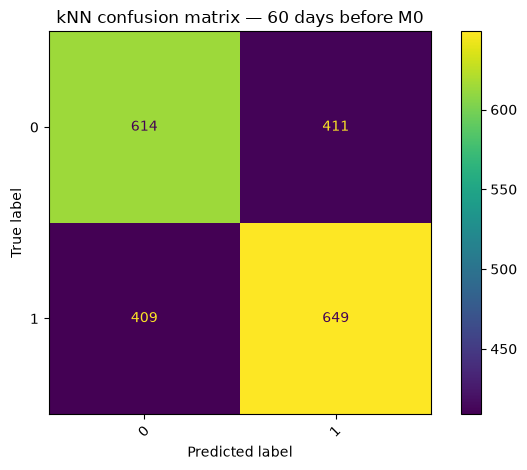


===== 30 days before M0 =====
              precision    recall  f1-score   support

           0       0.62      0.63      0.62      1025
           1       0.64      0.62      0.63      1058

    accuracy                           0.63      2083
   macro avg       0.63      0.63      0.63      2083
weighted avg       0.63      0.63      0.63      2083



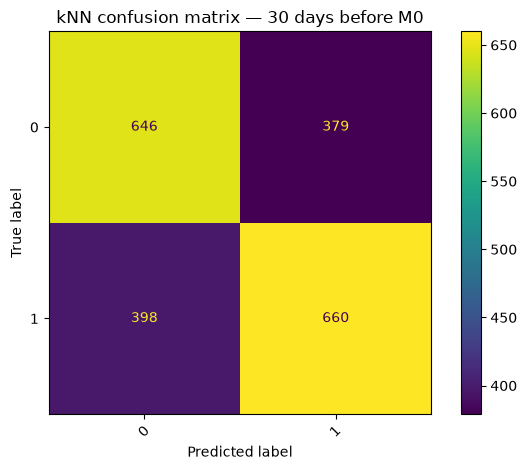


===== 0 days before M0 =====
              precision    recall  f1-score   support

           0       0.62      0.67      0.65      1025
           1       0.65      0.61      0.63      1058

    accuracy                           0.64      2083
   macro avg       0.64      0.64      0.64      2083
weighted avg       0.64      0.64      0.64      2083



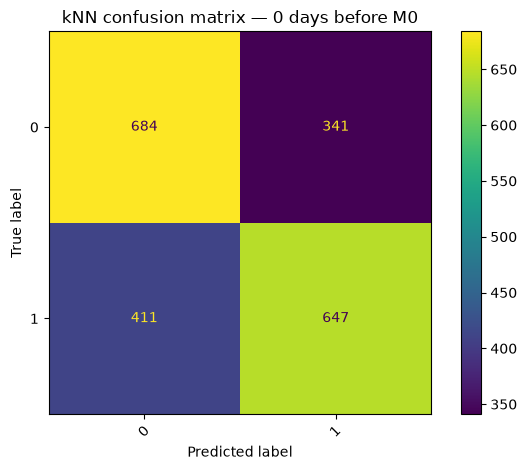

,n_train,n_test,accuracy,balanced_accuracy,macro_f1,weighted_f1
as_of_days,,,,,,
60,8416,2083,0.606337,0.606223,0.606226,0.606331
30,8416,2083,0.626980,0.627031,0.626963,0.627003
0,8416,2083,0.638982,0.639424,0.638868,0.638767


In [8]:
def grouped_holdout(X, y, groups, test_size=TEST_SIZE):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=RANDOM_STATE)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    return train_idx, test_idx

def build_knn_pipeline(n_neighbors=N_NEIGHBORS):
    numeric_pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )
    categorical_pipe = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore"),
    )
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, lambda X: X.select_dtypes(include=[np.number, "bool"]).columns.tolist()),
            ("cat", categorical_pipe, lambda X: X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()),
        ],
        remainder="drop",
    )
    return make_pipeline(
        preprocessor,
        KNeighborsClassifier(n_neighbors=n_neighbors, weights="distance"),
    )

model_results = []
fitted_models = {}
split_indices = {}

for days in AS_OF_DAYS:
    X, y, groups = X_by_time[days], y_by_time[days], groups_by_time[days]
    # Use stable row ordering before splitting.
    X = X.replace([np.inf, -np.inf], np.nan)
    train_idx, test_idx = grouped_holdout(X, y, groups)
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # kNN needs at least k training rows.
    k = min(N_NEIGHBORS, max(1, len(X_train) - 1))
    model = build_knn_pipeline(n_neighbors=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    fitted_models[days] = model
    split_indices[days] = (train_idx, test_idx)
    model_results.append({
        "as_of_days": days,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "macro_f1": __import__("sklearn.metrics", fromlist=["f1_score"]).f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "weighted_f1": __import__("sklearn.metrics", fromlist=["f1_score"]).f1_score(
            y_test, pred, average="weighted", zero_division=0
        ),
    })
    print(f"\n===== {days} days before M0 =====")
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)
    plt.title(f"kNN confusion matrix — {days} days before M0")
    plt.tight_layout()
    plt.show()

model_comparison = pd.DataFrame(model_results).set_index("as_of_days")
display(model_comparison)

## 7. Most important features: permutation importance

kNN does not provide native coefficients or feature importances. Permutation importance measures how much the held-out score decreases when one input feature is shuffled. We use **balanced accuracy** to be less dominated by the majority class.

This can be slow when there are many features and observations. Start with fewer repeats or a sample of the test set if needed. For one-hot encoded categorical fields, this implementation permutes the original input columns before preprocessing, which keeps each source feature interpretable.

Top 20 features — 60 days before M0


,feature,importance_mean,importance_std
89,grp_p2p_payments_share,0.010269,0.003390
138,run_min_balance_slog,0.009497,0.003833
131,run_in_income_informal_slog,0.009275,0.003816
112,run_grp_insurance_slog,0.008509,0.004041
140,balance_slog,0.008381,0.004866
101,run_essentials_slog,0.008101,0.001805
18,run_n_cash,0.007808,0.003292
122,run_grp_bank_fees_interest_slog,0.006848,0.006996
105,run_fees_slog,0.006848,0.006996
85,grp_debt_repayment_share,0.006586,0.003848


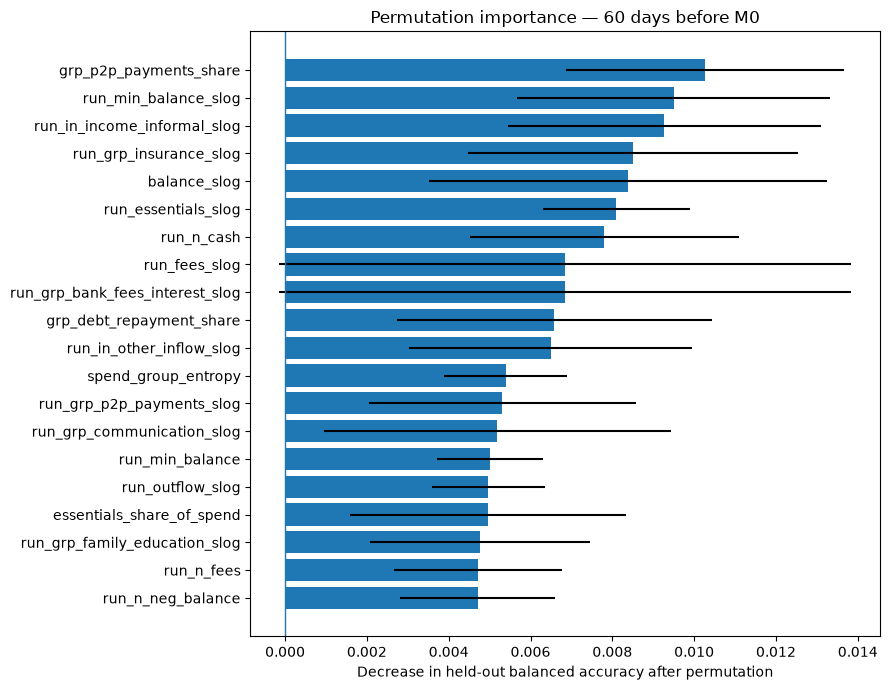

Top 20 features — 30 days before M0


,feature,importance_mean,importance_std
131,run_in_income_informal_slog,0.005439,0.004285
111,run_grp_transport_slog,0.004308,0.001967
84,grp_household_upkeep_share,0.004012,0.001142
44,run_in_borrowing,0.003842,0.002056
133,run_in_borrowing_slog,0.003812,0.002186
82,grp_personal_shopping_share,0.003656,0.003044
120,run_grp_household_upkeep_slog,0.003406,0.001262
59,net_per_day,0.003320,0.002401
17,run_n_bounced,0.003186,0.002228
69,gambling_share_of_spend,0.003153,0.001377


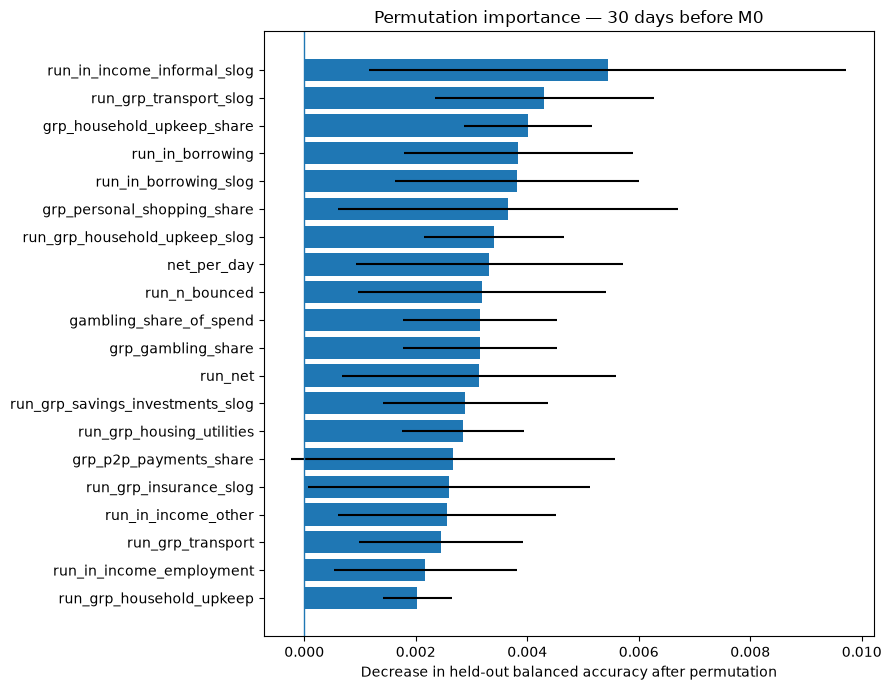

Top 20 features — 0 days before M0


,feature,importance_mean,importance_std
53,days_since_last_txn,0.008265,0.002914
116,run_grp_alcohol_tobacco_slog,0.007503,0.001358
54,days_since_last_income,0.007427,0.001667
120,run_grp_household_upkeep_slog,0.005143,0.001963
40,run_in_income_employment,0.004726,0.001789
89,grp_p2p_payments_share,0.004686,0.001429
140,balance_slog,0.004656,0.004627
104,run_cash_slog,0.004400,0.004088
124,run_grp_cash_withdrawal_slog,0.004400,0.004088
50,run_min_balance,0.004223,0.001500


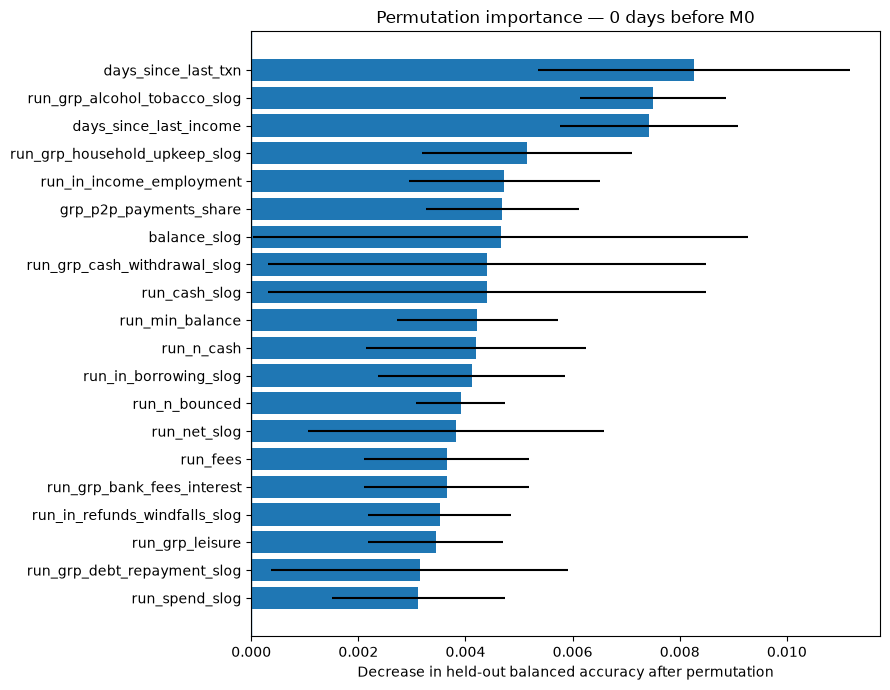

In [9]:
importance_by_time = {}

for days in AS_OF_DAYS:
    X, y, groups = X_by_time[days], y_by_time[days], groups_by_time[days]
    train_idx, test_idx = split_indices[days]
    X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
    model = fitted_models[days]

    # Optional cap for speed; keep the sample reproducible.
    if len(X_test) > 5000:
        sampled = X_test.sample(5000, random_state=RANDOM_STATE).index
        X_eval = X_test.loc[sampled]
        y_eval = y_test.loc[sampled]
    else:
        X_eval, y_eval = X_test, y_test

    perm = permutation_importance(
        model,
        X_eval,
        y_eval,
        scoring="balanced_accuracy",
        n_repeats=PERMUTATION_REPEATS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    importance = pd.DataFrame({
        "feature": X_eval.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }).sort_values("importance_mean", ascending=False)
    importance_by_time[days] = importance

    print(f"Top 20 features — {days} days before M0")
    display(importance.head(20))

    top = importance.head(20).sort_values("importance_mean")
    plt.figure(figsize=(9, 7))
    plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
    plt.axvline(0, linewidth=1)
    plt.xlabel("Decrease in held-out balanced accuracy after permutation")
    plt.title(f"Permutation importance — {days} days before M0")
    plt.tight_layout()
    plt.show()

## 8. Compare feature importance over time

as_of_days,0,30,60,mean_importance
feature,,,,
grp_p2p_payments_share,0.004686,0.002671,0.010269,0.005875
run_in_income_informal_slog,0.000000,0.005439,0.009275,0.004905
balance_slog,0.004656,0.000000,0.008381,0.004346
run_n_cash,0.004192,0.000000,0.007808,0.004000
run_min_balance_slog,0.000000,0.000000,0.009497,0.003166
run_min_balance,0.004223,0.000000,0.005009,0.003077
run_grp_household_upkeep_slog,0.005143,0.003406,0.000000,0.002850
run_grp_insurance_slog,0.000000,0.000000,0.008509,0.002836
days_since_last_txn,0.008265,0.000000,0.000000,0.002755


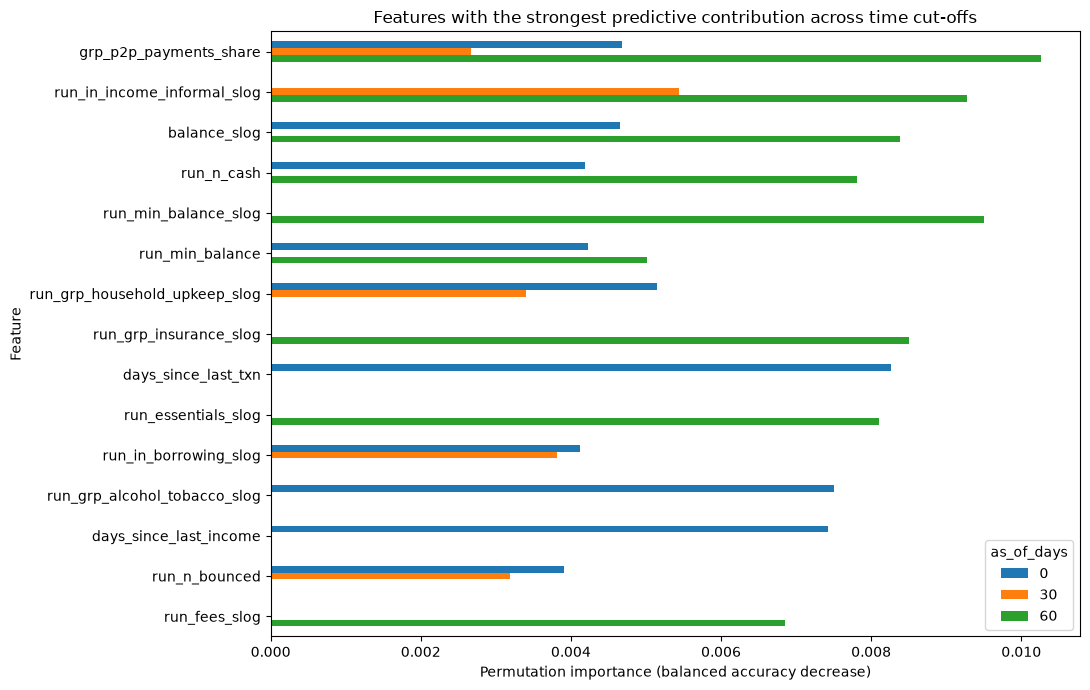

In [10]:
top_n = 15
importance_long = []
for days, imp in importance_by_time.items():
    temp = imp.head(top_n).copy()
    temp["as_of_days"] = days
    importance_long.append(temp)

importance_long = pd.concat(importance_long, ignore_index=True)
importance_pivot = importance_long.pivot_table(
    index="feature", columns="as_of_days", values="importance_mean", aggfunc="mean"
).fillna(0)

# Rank features by mean importance across the cut-offs.
importance_pivot["mean_importance"] = importance_pivot.mean(axis=1)
importance_pivot = importance_pivot.sort_values("mean_importance", ascending=False)
display(importance_pivot.head(25))

plot_data = importance_pivot.drop(columns="mean_importance").head(15)
plot_data.plot(kind="barh", figsize=(11, 7))
plt.xlabel("Permutation importance (balanced accuracy decrease)")
plt.ylabel("Feature")
plt.title("Features with the strongest predictive contribution across time cut-offs")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 9. Optional strict future-period evaluation

The customer-grouped holdout above prevents customer overlap, but does not guarantee that test observations occur after every training observation. For a true forward-looking evaluation, train on earlier M0 dates and test on later M0 dates. This can still contain customer overlap; if that is undesirable, remove test customers that appear in the training period.

Choose a date cutoff based on the operational question rather than tuning it to maximise scores.

In [11]:
days = AS_OF_DAYS[0]  # choose the cut-off to evaluate
X, y = X_by_time[days], y_by_time[days]
groups, dates = groups_by_time[days], dates_by_time[days]

valid_dates = dates.dropna()
if valid_dates.nunique() >= 2:
    cutoff = valid_dates.quantile(0.80)
    train_mask = dates < cutoff
    test_mask = dates >= cutoff

    # Optional: remove customers already seen in training to measure generalisation
    # to customers not represented in the training period.
    PURGE_SEEN_CUSTOMERS = True
    if PURGE_SEEN_CUSTOMERS:
        train_customers = set(groups.loc[train_mask])
        test_mask &= ~groups.isin(train_customers)

    X_train, y_train = X.loc[train_mask], y.loc[train_mask]
    X_test, y_test = X.loc[test_mask], y.loc[test_mask]

    if len(X_train) and len(X_test) and y_train.nunique() >= 1:
        k = min(N_NEIGHBORS, max(1, len(X_train) - 1))
        temporal_model = build_knn_pipeline(n_neighbors=k)
        temporal_model.fit(X_train, y_train)
        temporal_pred = temporal_model.predict(X_test)
        print(f"Temporal cutoff: {cutoff}")
        print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
        print("Balanced accuracy:", balanced_accuracy_score(y_test, temporal_pred))
        print(classification_report(y_test, temporal_pred, zero_division=0))
    else:
        print("The chosen cutoff/purge left too few train or test rows. Adjust the cutoff or disable PURGE_SEEN_CUSTOMERS.")
else:
    print("Not enough distinct valid M0 dates for a temporal split.")

Temporal cutoff: 2026-01-31 00:00:00
Train rows: 6,510; test rows: 1,849
Balanced accuracy: 0.5411006952287729
              precision    recall  f1-score   support

           0       0.66      0.60      0.63      1165
           1       0.41      0.48      0.45       684

    accuracy                           0.56      1849
   macro avg       0.54      0.54      0.54      1849
weighted avg       0.57      0.56      0.56      1849



## 10. Export results

Save tables so you can compare experiments without rerunning the full feature engineering.

In [12]:
OUT_DIR = Path("analysis_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

model_comparison.to_csv(OUT_DIR / "knn_time_cutoff_comparison.csv")
for days, imp in importance_by_time.items():
    imp.to_csv(OUT_DIR / f"permutation_importance_{days}d.csv", index=False)
for days, profile in cluster_profiles.items():
    profile.to_csv(OUT_DIR / f"cluster_profiles_{days}d.csv")

print(f"Saved analysis outputs to: {OUT_DIR.resolve()}")

Saved analysis outputs to: /Users/hoyle/Documents/Uni/4th_Year/MOR441-CAP/MOR-assignment3/analysis_outputs


# Full Transaction History Discovery

## 1. Config

In [15]:
RANDOM_STATE = 0
CLIENTS_PATH = Path("cleaned/clients_clean.parquet")
TRANSACTIONS_PATH = Path("cleaned/transactions_clean.parquet")

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"
M0_DATE = "m0_monthenddate"

N_CLUSTERS = 6
N_NEIGHBORS = 24
TEST_SIZE = 0.20
PERMUTATION_REPEATS = 5
MAX_OBSERVATIONS = None  # set to an integer for a quick test run
OUT_DIR = Path("analysis_outputs_full_history")

## 2. Load and Validate

In [16]:
from clean_data import load_and_clean
clients, transactions, report = load_and_clean("snapshot/snapshot.parquet")

Observation key: ['obs_id']
Observation-level columns (17): ['cifwithcheckdigit', 'obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag']
Transaction-level columns (8): ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname']
Ignored when matching duplicates (row counters): []
Building clients table ...
  4,482,046 raw rows -> 10,499 observations (4,999 customers) (2s)
Building transactions table ...
  transactions batch 1/1: 3,534,387 rows kept (4s)
CLIENTS (one row per observation)                                             
  raw rows (observation fields repeated per transaction)             4,482,046
  observations after cleaning                                           10,499
  distinct

## 3. Build transaction features using all available pre-M0 history

In [17]:
# Remove the feature builder's 92-day lookback limit.
ft.WINDOW_DAYS = np.inf

X_features = ft.build_running_features(
    clients=clients,
    txns=transactions,
    as_of=0,
    batch_customers=20_000,
    by_group=True,
    log_money=True,
    verbose=True,
)

print("Feature matrix:", X_features.shape)
display(X_features.head())

  running features batch 1/1 done
Feature matrix: (10499, 142)


,cifwithcheckdigit,run_n_txn,run_inflow,run_outflow,run_net,run_spend,run_income,run_essentials,run_nonessential,run_gambling,...,run_in_income_informal_slog,run_in_income_unemployment_slog,run_in_borrowing_slog,run_in_savings_drawdown_slog,run_in_refunds_windfalls_slog,run_in_transfers_in_slog,run_in_other_inflow_slog,run_min_balance_slog,run_max_balance_slog,balance_slog
obs_id,,,,,,,,,,,,,,,,,,,,,
167,100195245,190.0,206937.72,114934.41,92003.31,114194.96,79322.92,38843.97,2605.74,0.0,...,7.613908,0.0,11.038513,0.0,5.962576,6.607258,11.038745,-10.547025,10.070739,2.169054
168,100195245,201.0,309279.76,127550.84,181728.92,126802.07,115658.01,29744.11,725.94,0.0,...,8.682009,0.0,11.443973,0.0,5.707110,6.619766,11.444036,-10.547025,10.124668,8.919961
169,100195245,165.0,260722.98,97641.28,163081.70,97325.44,69504.96,24707.37,0.00,0.0,...,8.276649,0.0,11.443973,0.0,5.707110,5.758397,11.443973,-10.554727,10.124668,3.698335
170,100195245,188.0,335227.74,153294.55,181933.19,153266.67,140479.52,21830.19,0.00,0.0,...,8.975271,0.0,11.443973,0.0,0.000000,3.363149,11.445514,-10.554727,10.124668,7.561439
171,100195245,185.0,316651.48,139958.48,176693.00,139935.96,123832.56,22304.80,0.00,0.0,...,8.696380,0.0,11.443973,0.0,0.000000,3.157851,11.445514,-10.559351,10.095591,8.961839


## 4. Align features, target, and customer groups

In [18]:
EXCLUDE_EXACT = {
    TARGET, "target_rule", "total_paid", "payment_count",
    OBS_ID, CUSTOMER_ID, M0_DATE,
}
EXCLUDE_PREFIXES = ("target_",)

meta = clients.set_index(OBS_ID)
ids = X_features.index.intersection(meta.index)

X = X_features.loc[ids].copy()
y = meta.loc[ids, TARGET].copy()
groups = meta.loc[ids, CUSTOMER_ID].copy()

valid = y.notna() & groups.notna()
X, y, groups = X.loc[valid], y.loc[valid], groups.loc[valid]

drop_cols = [
    c for c in X.columns
    if c in EXCLUDE_EXACT or any(str(c).startswith(p) for p in EXCLUDE_PREFIXES)
]
X = X.drop(columns=drop_cols, errors="ignore")

for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype("int8")

X = X.replace([np.inf, -np.inf], np.nan)
print("Model observations:", len(X))
print("Predictor columns:", X.shape[1])
print("Overall target rate:", round(y.mean(), 4))

Model observations: 10499
Predictor columns: 141
Overall target rate: 0.5194


## 5. Cluster observations and profile them

In [19]:
def numeric_matrix(frame):
    numeric = frame.select_dtypes(include=[np.number, "bool"]).copy()
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    numeric = numeric.dropna(axis=1, how="all")
    numeric = numeric.loc[:, numeric.nunique(dropna=True) > 1]
    return numeric

X_num = numeric_matrix(X)
cluster_prep = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)
Z = cluster_prep.fit_transform(X_num)

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=10,
)
labels = kmeans.fit_predict(Z)

if len(Z) > 5000:
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(len(Z), size=5000, replace=False)
    silhouette = silhouette_score(Z[sample_idx], labels[sample_idx])
elif len(np.unique(labels)) > 1 and len(Z) > N_CLUSTERS:
    silhouette = silhouette_score(Z, labels)
else:
    silhouette = np.nan

cluster_results = pd.DataFrame(
    {"cluster": labels, "target": y.reindex(X_num.index)}
)
cluster_profiles = X_num.assign(cluster=labels).groupby("cluster").mean(numeric_only=True)
cluster_profiles["n_observations"] = cluster_results.groupby("cluster").size()
cluster_profiles["target_rate"] = cluster_results.groupby("cluster")["target"].mean()
cluster_profiles["share_of_observations"] = (
    cluster_profiles["n_observations"] / len(cluster_results)
)

print(f"Silhouette score: {silhouette:.3f}")
display(
    cluster_profiles[["n_observations", "share_of_observations", "target_rate"]]
    .sort_values("target_rate", ascending=False)
)

Silhouette score: 0.076


,n_observations,share_of_observations,target_rate
cluster,,,
0,686,0.065340,0.794461
4,2787,0.265454,0.621098
2,559,0.053243,0.617174
3,92,0.008763,0.500000
5,4319,0.411373,0.471405
1,2056,0.195828,0.364786


## Cluster sizes and target rates

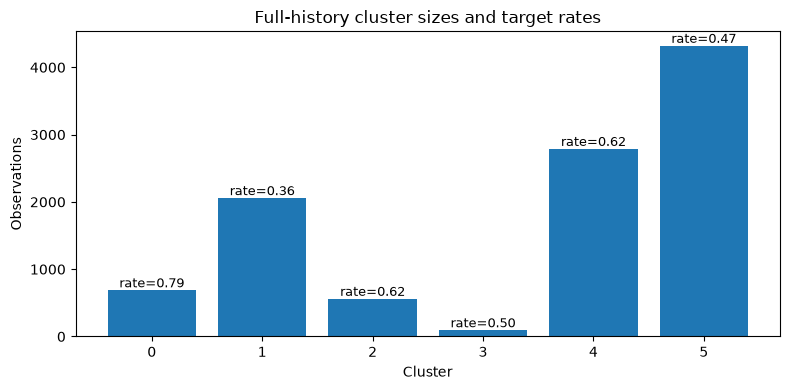

In [20]:
plot_data = cluster_profiles.sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(plot_data.index.astype(str), plot_data["n_observations"])
ax.set_xlabel("Cluster")
ax.set_ylabel("Observations")
ax.set_title("Full-history cluster sizes and target rates")
for bar, rate in zip(bars, plot_data["target_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"rate={rate:.2f}",
        ha="center", va="bottom", fontsize=9,
    )
plt.tight_layout()
plt.show()

## Features distinguishing clusters

In [21]:
def cluster_standardised_differences(frame, labels):
    frame = numeric_matrix(frame)
    overall_mean = frame.mean()
    overall_sd = frame.std().replace(0, np.nan)
    result = {}
    labels = np.asarray(labels)
    for cluster_id in sorted(np.unique(labels)):
        in_cluster = frame.iloc[np.flatnonzero(labels == cluster_id)]
        result[cluster_id] = (
            (in_cluster.mean() - overall_mean) / overall_sd
        ).sort_values(key=lambda values: values.abs(), ascending=False)
    return pd.DataFrame(result)

cluster_differences = cluster_standardised_differences(X_num, labels)
for cluster_id in cluster_differences.columns:
    print(f"Cluster {cluster_id}: strongest distinguishing features")
    display(cluster_differences[cluster_id].reindex(
        cluster_differences[cluster_id].abs().sort_values(ascending=False).head(15).index
    ).to_frame("standardised_difference"))

Cluster 0: strongest distinguishing features


,standardised_difference
grp_bank_fees_interest_share,3.087388
fees_share_of_spend,3.087388
run_essentials_slog,-2.663661
run_max_balance_slog,-2.585123
run_income_slog,-2.556494
no_income_seen,2.412935
run_spend_slog,-2.407353
run_outflow_slog,-2.407318
spend_group_entropy,-2.173068
run_in_income_other_slog,-2.171376


Cluster 1: strongest distinguishing features


,standardised_difference
run_n_purchases,1.221568
run_n_txn,1.188671
n_txn_per_day,1.172605
run_essentials,1.080970
run_inflow_slog,1.069262
run_outflow_slog,1.009547
run_spend_slog,1.000868
n_spend_groups_used,0.979554
run_grp_transport_slog,0.957797
run_spend,0.943776


Cluster 2: strongest distinguishing features


,standardised_difference
run_uif_slog,4.077551
run_in_income_unemployment_slog,4.077551
unemployed_now,4.040239
days_since_last_uif,-3.580815
run_in_income_unemployment,3.501770
run_uif,3.501770
run_income_slog,-0.585136
run_in_income_employment_slog,-0.474664
run_in_income_employment,-0.466268
run_in_borrowing_slog,0.458101


... (2 outputs left out)

Cluster 4: strongest distinguishing features


,standardised_difference
n_spend_groups_used,-0.848626
run_grp_eating_out_slog,-0.791479
run_grp_personal_shopping_slog,-0.780761
run_inflow_slog,-0.735154
run_nonessential_slog,-0.728238
run_n_purchases,-0.726730
run_n_txn,-0.723376
n_txn_per_day,-0.719578
run_grp_transport_slog,-0.715973
run_grp_p2p_payments_slog,-0.712576


Cluster 5: strongest distinguishing features


,standardised_difference
n_spend_groups_used,0.410832
run_nonessential_slog,0.391160
run_grp_p2p_payments_slog,0.376324
spend_group_entropy,0.371963
run_grp_communication_slog,0.346877
run_essentials_slog,0.343494
run_grp_food_groceries_slog,0.341440
run_grp_personal_shopping_slog,0.314702
days_since_last_income,-0.314119
run_income_slog,0.308379


## 6. kNN classification

In [22]:
splitter = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

k = min(N_NEIGHBORS, max(1, len(X_train) - 1))
knn = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k, weights="distance"),
)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

print(f"Train rows: {len(train_idx):,}; test rows: {len(test_idx):,}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, pred):.4f}")
print(classification_report(y_test, pred, zero_division=0))

Train rows: 8,416; test rows: 2,083
Balanced accuracy: 0.6289
              precision    recall  f1-score   support

           0       0.61      0.66      0.64      1025
           1       0.64      0.60      0.62      1058

    accuracy                           0.63      2083
   macro avg       0.63      0.63      0.63      2083
weighted avg       0.63      0.63      0.63      2083



## 7. Held-out permutation importance

,feature,importance_mean,importance_std
40,run_in_income_employment,0.004518,0.001254
134,run_in_savings_drawdown_slog,0.003637,0.001175
116,run_grp_alcohol_tobacco_slog,0.002927,0.005301
19,run_grp_food_groceries,0.002445,0.001625
84,grp_household_upkeep_share,0.002396,0.001335
24,run_grp_health,0.002290,0.000480
81,grp_gambling_share,0.002195,0.000986
69,gambling_share_of_spend,0.002195,0.000986
41,run_in_income_other,0.001906,0.001245
114,run_grp_family_education_slog,0.001851,0.004788


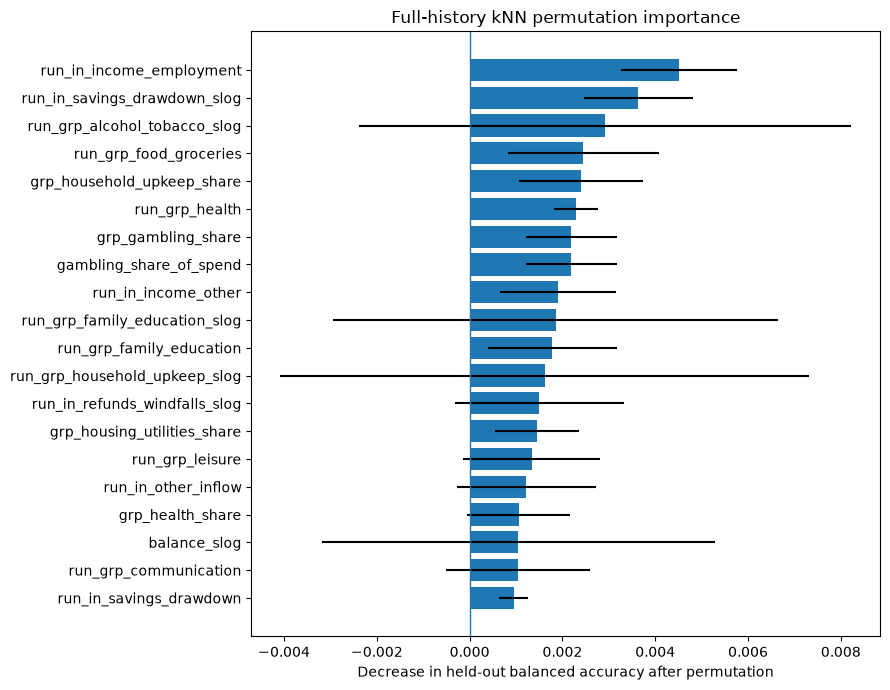

In [23]:
if len(X_test) > 5000:
    eval_ids = X_test.sample(5000, random_state=RANDOM_STATE).index
    X_eval, y_eval = X_test.loc[eval_ids], y_test.loc[eval_ids]
else:
    X_eval, y_eval = X_test, y_test

perm = permutation_importance(
    knn,
    X_eval,
    y_eval,
    scoring="balanced_accuracy",
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = pd.DataFrame({
    "feature": X_eval.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance.head(25))

top = importance.head(20).sort_values("importance_mean")
plt.figure(figsize=(9, 7))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.axvline(0, linewidth=1)
plt.xlabel("Decrease in held-out balanced accuracy after permutation")
plt.title("Full-history kNN permutation importance")
plt.tight_layout()
plt.show()

In [24]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

cluster_profiles.to_csv(OUT_DIR / "cluster_profiles_full_history.csv")
cluster_results.to_csv(OUT_DIR / "cluster_assignments_full_history.csv", index_label=OBS_ID)
cluster_differences.to_csv(OUT_DIR / "cluster_feature_differences_full_history.csv")
importance.to_csv(OUT_DIR / "permutation_importance_full_history.csv", index=False)

metrics = pd.DataFrame([{
    "n_observations": len(X),
    "n_train": len(train_idx),
    "n_test": len(test_idx),
    "n_features": X.shape[1],
    "n_clusters": N_CLUSTERS,
    "silhouette": silhouette,
    "balanced_accuracy": balanced_accuracy_score(y_test, pred),
}])
metrics.to_csv(OUT_DIR / "model_metrics_full_history.csv", index=False)

print(f"Saved outputs to: {OUT_DIR.resolve()}")

Saved outputs to: /Users/hoyle/Documents/Uni/4th_Year/MOR441-CAP/MOR-assignment3/analysis_outputs_full_history
